In [1]:
import numpy as nmp
from netCDF4 import Dataset as ncd
from netCDF4 import num2date, date2num
import matplotlib.pyplot as plt
import os


from specialized_input_data.specialized_input_data import *

### Creation of netCDF file from DB19 samples in 8 size bins

C:\Users\miguel.huerta\AppData\Local\Temp\ipykernel_3080\1573043708.py:104: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  FBIN[s] = nmp.trapz(MDIST[AB],x=RAD[AB])


Tun: [ 0.24  0.82  5.24 11.24 29.93 40.02 12.51  0.  ] % | Total: 1.0000
Mor: [ 0.11  0.4   3.91  8.38 32.77 43.31 11.13  0.  ] % | Total: 1.0000
Lib: [ 0.14  0.55  5.09 10.2  36.84 43.18  4.01  0.  ] % | Total: 1.0000
Alg: [ 0.07  0.27  2.6   4.79 23.9  50.48 17.89  0.  ] % | Total: 1.0000
Mau: [ 0.22  0.64  5.13 10.6  35.04 44.41  3.97  0.  ] % | Total: 1.0000
Nig: [ 0.1   0.36  3.08  7.59 25.73 47.17 15.98  0.  ] % | Total: 1.0000
Mal: [ 0.32  0.68  5.19 10.36 43.96 38.44  1.04  0.  ] % | Total: 1.0000
Bod: [ 0.08  0.29  2.04  4.   18.98 43.46 31.15  0.  ] % | Total: 1.0000
Eth: [ 0.06  0.25  2.69  5.35 26.13 43.48 22.04  0.  ] % | Total: 1.0000
Sau: [ 0.19  0.62  5.97  8.95 32.86 45.49  5.92  0.  ] % | Total: 1.0000
Kuw: [ 0.15  0.45  3.28  7.33 28.69 36.16 23.94  0.  ] % | Total: 1.0000
Gob: [ 0.36  1.13  6.39 12.41 28.64 38.72 12.34  0.  ] % | Total: 1.0000
Ari: [ 0.12  0.37  4.07  6.   22.46 47.21 19.77  0.  ] % | Total: 1.0000
Ata: [ 0.08  0.3   4.23  9.47 33.29 42.28 10.35  0.

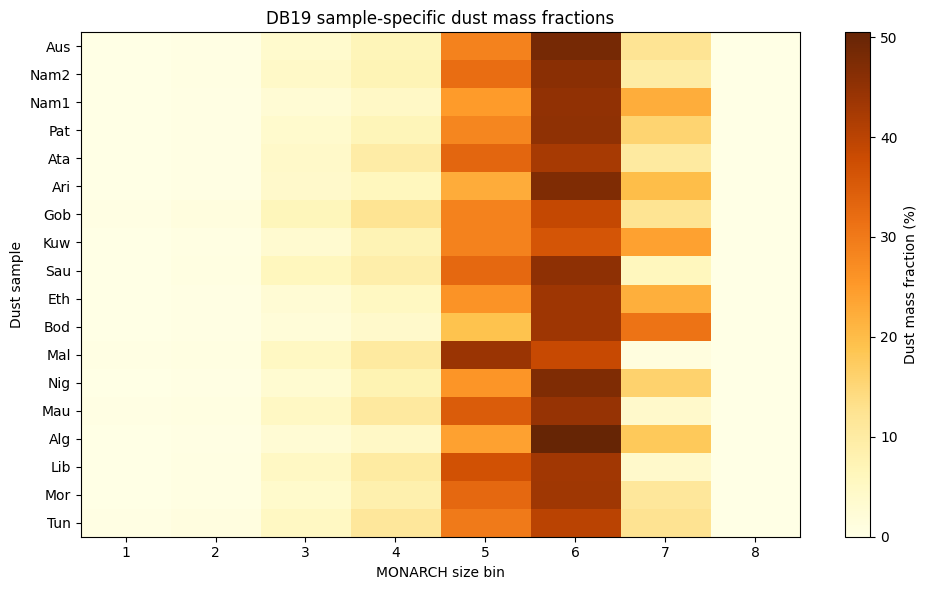

In [2]:
# ==========================================================
# 1. CONFIGURATION
# ==========================================================

output_file = 'dust_mineral_fractions_DB19sites.nc'
site_names = ['Tun','Mor','Lib','Alg','Mau','Nig','Mal','Bod','Eth','Sau','Kuw','Gob','Ari','Ata','Pat','Nam1','Nam2','Aus']
NSITE = len(site_names)



# ==========================================================
# 2. SIZE DISTRIBUTION: Di Biagio et al. (2019), Table S1
# ==========================================================

# DB19 - Supplementary Table S1
# Dg: geometric median diameter (um)
# sigma: geometric standard deviation (-)
# Nmode: total number concentration (cm-3)
# Order: Tun, Mor, Lib, Alg, Mau, Nig, Mal, Bod, Eth, Sau,
#        Kuw, Gob, Ari, Ata, Pat, Nam1, Nam2, Aus

Dg = nmp.array([
    [0.27,0.69,1.4,2.6,3.9],
    [0.28,0.75,1.5,2.8,4.8],
    [0.27,0.73,1.5,2.4,3.3],
    [0.29,0.77,1.6,2.8,4.5],
    [0.25,0.72,1.5,2.7,4.2],
    [0.24,0.69,1.4,2.4,3.6],
    [0.24,0.75,1.6,2.5,3.4],
    [0.34,0.85,1.7,2.8,4.3],
    [0.28,0.76,1.6,2.7,4.2],
    [0.29,0.79,1.7,2.0,3.3],
    [0.24,0.71,1.5,2.8,4.3],
    [0.25,0.67,1.4,2.6,3.9],
    [0.29,0.82,2.0,2.0,4.5],
    [0.27,0.78,1.6,2.6,3.8],
    [0.27,0.78,1.7,2.8,4.5],
    [0.29,0.79,1.7,2.9,4.2],
    [0.26,0.77,1.7,2.6,3.7],
    [0.27,0.79,1.6,2.6,3.8]
])

sigma = nmp.array([
    [1.50,1.30,1.30,1.19,1.31],
    [1.50,1.30,1.30,1.23,1.20],
    [1.50,1.30,1.30,1.11,1.29],
    [1.50,1.30,1.30,1.20,1.25],
    [1.50,1.30,1.30,1.17,1.20],
    [1.50,1.30,1.30,1.15,1.35],
    [1.51,1.30,1.30,1.11,1.23],
    [1.50,1.30,1.30,1.19,1.35],
    [1.50,1.30,1.30,1.18,1.32],
    [1.50,1.30,1.30,1.30,1.31],
    [1.56,1.30,1.30,1.19,1.35],
    [1.50,1.30,1.30,1.17,1.31],
    [1.50,1.30,1.41,1.35,1.27],
    [1.50,1.30,1.30,1.17,1.30],
    [1.50,1.30,1.30,1.20,1.25],
    [1.50,1.30,1.30,1.17,1.32],
    [1.50,1.30,1.30,1.13,1.30],
    [1.50,1.30,1.30,1.13,1.30]
])

Nmode = nmp.array([
    [1050,507,221,49,36],
    [342,260,104,54,13],
    [527,445,158,23,67],
    [267,207,65,37,26],
    [269,139,51,17,8],
    [468,305,150,31,58],
    [234,76,26,6,10],
    [1967,828,319,129,189],
    [460,443,148,72,59],
    [652,440,102,4,61],
    [283,126,50,19,10],
    [1061,456,161,28,23],
    [1261,858,285,10,66],
    [1144,1278,514,149,142],
    [526,353,113,47,28],
    [665,394,124,52,57],
    [496,291,76,21,34],
    [483,224,77,23,35]
])

assert bmas.shape[1] == NSITE
assert Dg.shape == sigma.shape == Nmode.shape == (NSITE,5)

# Five log-normal modes per sample. Dg in um, sigma dimensionless,
# Nmode in cm-3. Diameter is converted to radius; r^3 weighting
# converts the number distribution into a mass-proportional distribution.

def SizeMassFractions_DB19(Dg,sigma,Nmode):
    RAD = nmp.geomspace(max(0.01,min(sbin)),min(5.0,max(sbax)),200000)
    NDIST = nmp.zeros_like(RAD)
    for i in range(5):
        rg = Dg[i]/2.0
        ls = nmp.log(sigma[i])
        NDIST += Nmode[i]/(nmp.sqrt(2*nmp.pi)*ls*RAD)*nmp.exp(-(nmp.log(RAD/rg))**2/(2*ls**2))
    MDIST = RAD**3*NDIST
    FBIN = nmp.zeros(S)
    for s in range(S):
        AB = (RAD>=sbin[s])&(RAD<=sbax[s])
        if nmp.any(AB):
            FBIN[s] = nmp.trapz(MDIST[AB],x=RAD[AB])
    if FBIN.sum()<=0:
        raise ValueError('No dust mass within defined size bins.')
    return FBIN/FBIN.sum()

SIZEFRAC = nmp.array([SizeMassFractions_DB19(Dg[i],sigma[i],Nmode[i]) for i in range(NSITE)])

for i in range(NSITE):
    print(f'{site_names[i]}: {nmp.round(SIZEFRAC[i]*100,2)} % | Total: {SIZEFRAC[i].sum():.4f}')

# ==========================================================
# 3. MINERAL MASS FRACTIONS
# ==========================================================

BHEMA = bmas[4,:]/100.0
BGOET = bmas[5,:]/100.0
BHOST = 1.0-BHEMA-BGOET

HEMA = nmp.tile(BHEMA[:,None],(1,S))
GOET = nmp.tile(BGOET[:,None],(1,S))
HOST = nmp.tile(BHOST[:,None],(1,S))

print('\nDimensions:',HOST.shape,HEMA.shape,GOET.shape,SIZEFRAC.shape)
print('Maximum mineral fraction deviation:',nmp.max(nmp.abs(HOST+HEMA+GOET-1.0)))

# ==========================================================
# 4. CREATE NETCDF
# ==========================================================

out = ncd(output_file,'w',format='NETCDF4')
out.createDimension('Site',NSITE)
out.createDimension('S',S)
out.createDimension('Mode',5)

SITE = out.createVariable('Site',str,('Site',))
SITE.long_name = 'Dust sampling site'
SITE[:] = nmp.array(site_names,dtype=object)

BIN = out.createVariable('S','i4',('S',))
BIN.long_name = 'Dust size bin'
BIN[:] = nmp.arange(1,S+1)

for name,data,units,long_name,dims in [
    ('RMIN',sbin,'um','Minimum particle radius',('S',)),
    ('RMAX',sbax,'um','Maximum particle radius',('S',)),
    ('SIZEFRAC',SIZEFRAC,'-','Relative dust mass fraction per size bin',('Site','S')),
    ('hema',HEMA,'-','Hematite mass fraction',('Site','S')),
    ('goet',GOET,'-','Goethite mass fraction',('Site','S')),
    ('host',HOST,'-','Host mineral mass fraction',('Site','S')),
    ('Dg_mode',Dg,'um','Geometric mean diameter of DB19 modes',('Site','Mode')),
    ('sigma_mode',sigma,'-','Geometric standard deviation of DB19 modes',('Site','Mode')),
    ('Nmode',Nmode,'cm-3','Integrated number concentration of DB19 modes',('Site','Mode'))
]:
    var = out.createVariable(name,'f4',dims)
    var.units = units
    var.long_name = long_name
    var[:] = data

out.description = 'Mineral fractions and sample-specific dust size distributions'
out.size_distribution = 'Five-mode log-normal distribution, Di Biagio et al. (2019), Table S1'
out.size_distribution_cutoff = '10 um diameter (5 um radius)'
out.size_distribution_assumption = 'Mineral composition assumed constant across size bins'
out.close()

print('\nNetCDF successfully created:',output_file)

# ==========================================================
# 5. PLOT SIZE DISTRIBUTIONS
# ==========================================================

fig,ax = plt.subplots(figsize=(10,6))
im = ax.imshow(SIZEFRAC*100,aspect='auto',origin='lower',cmap='YlOrBr')
ax.set(xticks=nmp.arange(S),xticklabels=nmp.arange(1,S+1),yticks=nmp.arange(NSITE),yticklabels=site_names,xlabel='MONARCH size bin',ylabel='Dust sample',title='DB19 sample-specific dust mass fractions')
plt.colorbar(im,ax=ax,label='Dust mass fraction (%)')
plt.tight_layout()
plt.show()


### Mineral monochromatic Look-Up Table (Mie)

In [3]:
inp = ncd('Mie_IrOx_LUT/mineral_monochromatic_table_empirical_moreWL.nc', 'r') 
#This is a LUT of Mie properties for different: IrOx mass%, size bins and spectral bands
dens = (inp.variables['DENS'][:]).filled() # [S] (total dust, constant for all bins) (g cm-3)
reff = (inp.variables['REFF'][:]).filled() # [S] (um)
qext = (inp.variables['QEXT'][:,:]).filled() # [S,B_mono]
qsca = (inp.variables['QSCA'][:,:]).filled()
qasy = (inp.variables['QASY'][:,:]).filled()
vext = (inp.variables['VEXT'][:,:,:]).filled() #[S,B_mono,Im]
vsca = (inp.variables['VSCA'][:,:,:]).filled() 
vasy = (inp.variables['VASY'][:,:,:]).filled()
#Only if they were created in the Mie LUT (sometimes I don't fore time issues):
"""wext = (inp.variables['WEXT'][:,:,:,:]).filled() # [S,B_mono,Im,Im]
wsca = (inp.variables['WSCA'][:,:,:,:]).filled()
wasy = (inp.variables['WASY'][:,:,:,:]).filled()"""

inp.close()

#Depending on which approach you use, you have to change the aux function ()

### Input of mass concentrations

In [4]:
#Here I should take only the mass loads from the selected pixel from monarch
#That will provide: mass% of hema, goet and host in the column. With mdnen I calculate vol%
# for each of monarch 8 size bins. They will be daily means (so no T=12)
#The only dims of the Thessaloniki mass% are Day (the day) and S (size bin)(8)

In [5]:
inp = ncd('dust_mineral_fractions_DB19sites.nc', 'r') 
#Dims are: 19 datetime64 (Day) x 8 size bins (S)
Site = inp.dimensions['Site'].size #site from samples
S = inp.dimensions['S'].size #monarch size bins
xhema = (inp.variables['hema'][:]).filled()
xgoet = (inp.variables['goet'][:]).filled()
xhost = (inp.variables['host'][:]).filled()
xiox = xhema + xgoet ###
mdust_frac = (inp.variables['SIZEFRAC'][:]).filled()
# Assumed dust column mass
TOTAL_DUST_MASS = 0.001  # g cm-2
# Distribute among size bins
mdust = TOTAL_DUST_MASS * mdust_frac

sufix = "DB_psd_mass3"

### MASS DENSITIES ###
#Only the mineral species given in EMIT+MONARC (11 witout mixes)

                 # Illi   Kaol   Mont   Chlo   Verm   Calc   Quar   Feld   Gyps   Hema   Goet
mden = nmp.array([2.570, 2.630, 2.570, 2.420, 2.300, 2.710, 2.670, 2.680, 2.308, 5.250, 4.180]) # (g cm-3)

In [6]:
"""
from matplotlib.lines import Line2D

base_path = r'C:/Users/Usuario/Desktop/BSC_secondment/'
files = {
    'Thess': 'monarch_massfract_thess_aeronet.nc',
    'DOD 01': 'monarch_massfract_thess_dod01.nc',
    'DOD 03': 'monarch_massfract_thess_dod03.nc',
    'DOD 05': 'monarch_massfract_thess_dod05.nc'
}

green = ['#8FBC8F', '#4F8B5B', '#276738', '#154421']
red = ['#E57373', '#D32F2F', '#A31515', '#720D0D']
gray = ['#202020', '#808080', '#505050', '#202020']

bins = nmp.arange(1, 9)
fig, ax1 = plt.subplots(figsize=(10, 6))
ax2 = ax1.twinx()

for i, (name, filename) in enumerate(files.items()):
    inp = ncd(os.path.join(base_path, filename), 'r')

    xhema = inp.variables['hema'][:].filled() * 100
    xgoet = inp.variables['goet'][:].filled() * 100
    mdust = inp.variables['dust_mass'][:].filled() * 0.1

    mean_xhema, std_xhema = nmp.mean(xhema, axis=0), nmp.std(xhema, axis=0)
    mean_xgoet, std_xgoet = nmp.mean(xgoet, axis=0), nmp.std(xgoet, axis=0)
    mean_mdust, std_mdust = nmp.mean(mdust, axis=0), nmp.std(mdust, axis=0)

    color_hema = 'blue' if i == 0 else green[i]
    color_goet = 'orange' if i == 0 else red[i]
    marker = 's' if i == 0 else 'o'
    linestyle = '--' if i == 0 else '-'

    ax1.errorbar(bins, mean_xhema, yerr=std_xhema, fmt=marker + linestyle, color=color_hema, capsize=4, linewidth=2)
    ax1.errorbar(bins, mean_xgoet, yerr=std_xgoet, fmt=marker + linestyle, color=color_goet, capsize=4, linewidth=2)
    ax2.errorbar(bins, mean_mdust, yerr=std_mdust, fmt=marker + linestyle, color=gray[i], linestyle=linestyle, capsize=4, linewidth=2)

    inp.close()

ax1.set_xlabel("Bin")
ax1.set_ylabel("Mass fraction (%)")
ax2.set_ylabel("Total dust mass (g/cm²)")
ax1.set_xticks(bins)
ax1.grid(alpha=0.3)

# Legend 1: variables and units
legend_left = [
    Line2D([0], [0], color='#D32F2F', linewidth=2, label='Goethite (%)'),
    Line2D([0], [0], color='#276738', linewidth=2, label='Hematite (%)'),
    Line2D([0], [0], color='black', linewidth=2, label='Total dust (g/cm²)')
]

leg1 = ax1.legend(handles=legend_left, loc='center left', bbox_to_anchor=(0.01, 0.5))
ax1.add_artist(leg1)

# Legend 2: experiment markers
legend_right = [
    Line2D([0], [0], color='black', marker='s', linestyle='--', markersize=7, label='AERONET filtered'),
    Line2D([0], [0], color='black', marker='o', linestyle='-', markersize=7, label='MONARCH DOD filtered')
]

ax2.legend(handles=legend_right, loc='center left', bbox_to_anchor=(0.01, 0.25))

plt.tight_layout()
plt.show()"""


'\nfrom matplotlib.lines import Line2D\n\nbase_path = r\'C:/Users/Usuario/Desktop/BSC_secondment/\'\nfiles = {\n    \'Thess\': \'monarch_massfract_thess_aeronet.nc\',\n    \'DOD 01\': \'monarch_massfract_thess_dod01.nc\',\n    \'DOD 03\': \'monarch_massfract_thess_dod03.nc\',\n    \'DOD 05\': \'monarch_massfract_thess_dod05.nc\'\n}\n\ngreen = [\'#8FBC8F\', \'#4F8B5B\', \'#276738\', \'#154421\']\nred = [\'#E57373\', \'#D32F2F\', \'#A31515\', \'#720D0D\']\ngray = [\'#202020\', \'#808080\', \'#505050\', \'#202020\']\n\nbins = nmp.arange(1, 9)\nfig, ax1 = plt.subplots(figsize=(10, 6))\nax2 = ax1.twinx()\n\nfor i, (name, filename) in enumerate(files.items()):\n    inp = ncd(os.path.join(base_path, filename), \'r\')\n\n    xhema = inp.variables[\'hema\'][:].filled() * 100\n    xgoet = inp.variables[\'goet\'][:].filled() * 100\n    mdust = inp.variables[\'dust_mass\'][:].filled() * 0.1\n\n    mean_xhema, std_xhema = nmp.mean(xhema, axis=0), nmp.std(xhema, axis=0)\n    mean_xgoet, std_xgoet = 

### Global optical interpolation (functions)

In [7]:
def GlbOpts(XHM,XGT,s1,wvl): #mass% of Hema and Goet, idx of a size bin, idx of wvl
 """
 Interpolates from the LUT the Mie properties to the given mass % of H and G, size bin and wvl
 The Mie properties are:
 - EXT: extinction efficiency
 - SCA: scattering "
 - ASY: asymmetry parameter
 """

 #Keeps the mass fractions inside the LUT range (0%->10%), without extrapolation
 XHM = float(nmp.clip(XHM, igrd[0], igrd[-1]))
 XGT = float(nmp.clip(XGT, igrd[0], igrd[-1]))

 #Finds the lower grid indices for bilinear interpolation
 h = int(nmp.clip(nmp.searchsorted(igrd, XHM, side='right')-1, 0, Im-2))
 g = int(nmp.clip(nmp.searchsorted(igrd, XGT, side='right')-1, 0, Im-2))
 #Takes the two bins from the grid that enclose the value
 HG1 = igrd[h]
 HG2 = igrd[h+1]
 GG1 = igrd[g]
 GG2 = igrd[g+1]

 #Calculates the weights of the 4 surrounding LUT points
 DHG = (HG2-HG1)*(GG2-GG1)
 W11 = (HG2-XHM)*(GG2-XGT)/DHG
 W12 = (HG2-XHM)*(XGT-GG1)/DHG
 W21 = (XHM-HG1)*(GG2-XGT)/DHG
 W22 = (XHM-HG1)*(XGT-GG1)/DHG

 #Interpolates extinction, scattering and asymmetry for the selected size and wavelength
 EXT = wext[s1,wvl,h,g]*W11 + wext[s1,wvl,h,g+1]*W12 + wext[s1,wvl,h+1,g]*W21 + wext[s1,wvl,h+1,g+1]*W22
 SCA = wsca[s1,wvl,h,g]*W11 + wsca[s1,wvl,h,g+1]*W12 + wsca[s1,wvl,h+1,g]*W21 + wsca[s1,wvl,h+1,g+1]*W22
 ASY = wasy[s1,wvl,h,g]*W11 + wasy[s1,wvl,h,g+1]*W12 + wasy[s1,wvl,h+1,g]*W21 + wasy[s1,wvl,h+1,g+1]*W22


 return EXT, SCA, ASY 

In [8]:
def GlbOpts_IrOx(XHM,XGT,s1,wvl): #mass% of Hema and Goet, idx of a size bin, idx of wvl
 #Does the exact same of previous function but for a single mass of IrOx species added up

 #Exactly all same steps than GlobOpts (see there) but for the sum of all iron oxides:
 XIOX = float(nmp.clip(XHM + XGT, igrd[0], igrd[-1])) 

 iox = int(nmp.clip(nmp.searchsorted(igrd, XIOX, side='right')-1, 0, Im-2))
 IOX1 = igrd[iox]
 IOX2 = igrd[iox+1]

 DIOX = IOX2-IOX1
 W1 = (IOX2-XIOX)/DIOX
 W2 = (XIOX-IOX1)/DIOX

 EXT_IOX = vext[s1,wvl,iox]*W1 + vext[s1,wvl,iox+1]*W2
 SCA_IOX = vsca[s1,wvl,iox]*W1 + vsca[s1,wvl,iox+1]*W2
 ASY_IOX = vasy[s1,wvl,iox]*W1 + vasy[s1,wvl,iox+1]*W2

 return EXT_IOX, SCA_IOX, ASY_IOX 

### Global optical properties

In [10]:
# Allocate results for all days
names = ['homogenous_dust', 'mixed_dust']
#to cencel/include homogenous case, just comment/descomment 'continue' in the 2 c loops

gext_all = nmp.zeros([2, Site, B_mono])
gsca_all = nmp.zeros([2, Site, B_mono])
gasy_all = nmp.zeros([2, Site, B_mono])


# This loop is adapted for MONARCH input where the pixel is already selected
# and dust masses have been integrated over the vertical levels.
# The total dust mass and mass fractions (hema, goet and host) 
#need to be given in terms of the 8 monarch size bins.

for site in nmp.arange(Site):

    print('Processing site: ', site)

    # Optical contributions for each size bin and wavelength
    dext, dsca, dasy = (nmp.zeros([S, B_mono]), nmp.zeros([S, B_mono]), nmp.zeros([S, B_mono]))
    mext, msca, masy = (nmp.zeros([S, B_mono]), nmp.zeros([S, B_mono]), nmp.zeros([S, B_mono]))

    for s in nmp.arange(S):

        DEN = dens[s]          # g cm-3
        REF = reff[s] * 1e-4  # um -> cm
        QTK = 3.0 / (4.0 * DEN * REF)

        MDU = mdust[site, s]     # g cm-2

        XHM = xhema[site, s]
        XGT = xgoet[site, s]

        for b in nmp.arange(B_mono):

            # Homogeneous mixture
            EXT = qext[s, b]
            SCA = qsca[s, b]
            ASY = qasy[s, b]

            dext[s, b] = EXT * QTK * MDU
            dsca[s, b] = SCA * QTK * MDU
            dasy[s, b] = ASY

            # Varying mineral mixture
            #EXT, SCA, ASY = GlbOpts(XHM, XGT, s, b)
            EXT, SCA, ASY = GlbOpts_IrOx(XHM, XGT, s, b)
            #Dont need to change anything from V to W (INB=1 -> 2) if the function is already changed 

            mext[s, b] = EXT * QTK * MDU
            msca[s, b] = SCA * QTK * MDU
            masy[s, b] = ASY

    # Reference extinction: all size bins, mixed composition
    gext = nmp.sum(mext, axis=0)

    # --------------------------------------------------
    # Calculate the homogenous and mixed cases

    for c in nmp.arange(2):

        if c == 0:
            continue
            # Homogeneous
            bext = nmp.sum(dext, axis=0)
            bsca = nmp.sum(dsca, axis=0)
            gsca = nmp.divide(
                bsca * gext, bext,
                out=nmp.zeros_like(bsca),
                where=bext != 0
            )
            scat = dsca
            asym = dasy

        if c == 1:
            # Mixed minerals or sum of irox species as one (iox)
            bext = nmp.sum(mext, axis=0)
            bsca = nmp.sum(msca, axis=0)
            gsca = nmp.divide(
                bsca * gext, bext,
                out=nmp.zeros_like(bsca),
                where=bext != 0
            )
            scat = msca
            asym = masy

        # Scattering-weighted asymmetry parameter
        scat_sum = nmp.sum(scat, axis=0)
        gasy = nmp.divide(
            nmp.sum(asym * scat, axis=0),
            scat_sum,
            out=nmp.zeros(B_mono),
            where=scat_sum != 0
        )

        # Store results for this day and PM case
        gext_all[c, site, :] = gext
        gsca_all[c, site, :] = gsca
        gasy_all[c, site, :] = gasy


# --------------------------------------------------
# Write one NetCDF file per PM case, containing all days

for c in nmp.arange(2):

    if c == 0:
        continue
    
    out = ncd(f'SSA_ext_DB19/%s_{sufix}.nc' % names[c], 'w', format='NETCDF4')

    out.createDimension('Site', Site)
    out.createDimension('B_mono', B_mono)

    # Wavelength coordinate
    WVL = out.createVariable('wavelength', 'f4', ('B_mono',))
    WVL.units = 'um'
    WVL.long_name = 'Monochromatic wavelength'
    WVL[:] = wvl_micron

    # Extinction optical depth
    GEXT = out.createVariable('GEXT', 'f4', ('Site', 'B_mono'))
    GEXT.units = '-'
    GEXT.long_name = 'Dust column extinction optical depth'

    # Scattering optical depth
    GSCA = out.createVariable('GSCA', 'f4', ('Site', 'B_mono'))
    GSCA.units = '-'
    GSCA.long_name = 'Dust column scattering optical depth'

    # Asymmetry parameter
    GASY = out.createVariable('GASY', 'f4', ('Site', 'B_mono'))
    GASY.units = '-'
    GASY.long_name = 'Dust asymmetry parameter'

    GEXT[:, :] = gext_all[c, :, :]
    GSCA[:, :] = gsca_all[c, :, :]
    GASY[:, :] = gasy_all[c, :, :]

    out.close()

Processing site:  0
Processing site:  1
Processing site:  2
Processing site:  3
Processing site:  4
Processing site:  5
Processing site:  6
Processing site:  7
Processing site:  8
Processing site:  9
Processing site:  10
Processing site:  11
Processing site:  12
Processing site:  13
Processing site:  14
Processing site:  15
Processing site:  16
Processing site:  17


### Plotting the SSA results

In [14]:
samples = ['Tun','Mor','Lib','Alg','Mau','Nig','Mal','Bod','Eth','Sau','Kuw','Gob','Ari','Ata','Pat','Nam1','Nam2','Aus']

groups = [
    ('Northern Africa - Sahara', [0,1,2,3,4], ['#e6a500','#ffcc00','#e83e8c','#ff0000','#e64b00']),
    ('Sahel', [5,6,7], ['#9b9bff','#00a6d6','#003b9e']),
    ('Eastern Africa - Middle East', [8,9,10], ['#a6e600','#b5d900','#009b39']),
    ('Eastern Asia', [11], ['#ed35a5']),
    ('North America', [12], ['#808080']),
    ('South America', [13,14], ['#66a6a6','#245f60']),
    ('Southern Africa', [15,16], ['#e6a500','#ff4b16']),
    ('Australia', [17], ['#8000ff'])
]

# Wavelengths in micrometres
bwvl_ssa = nmp.array([0.37, 0.47, 0.52, 0.59, 0.66])

# Published SSA values from Di Biagio et al. (2019)
# Rows = samples
# Columns = wavelengths
ssa_biri = nmp.array([
    [0.85, 0.90, 0.93, 0.95, 0.95],  # Tunisia
    [0.92, 0.95, 0.96, 0.98, 0.98],  # Morocco
    [0.89, 0.93, 0.95, 0.98, 0.98],  # Libya
    [0.87, 0.92, 0.94, 0.97, 0.97],  # Algeria
    [0.85, 0.90, 0.94, 0.96, 0.97],  # Mauritania
    [0.72, 0.85, 0.89, 0.91, 0.92],  # Niger
    [0.75, 0.85, 0.89, 0.93, 0.95],  # Mali
    [0.96, 0.98, 0.98, 0.99, 0.99],  # Bodélé
    [0.80, 0.86, 0.90, 0.92, 0.94],  # Ethiopia
    [0.88, 0.93, 0.96, 0.98, 0.98],  # Saudi Arabia
    [0.95, 0.97, 0.98, 0.98, 0.99],  # Kuwait
    [0.88, 0.92, 0.94, 0.96, 0.97],  # Gobi
    [0.93, 0.96, 0.97, 0.98, 0.98],  # Arizona
    [0.89, 0.93, 0.94, 0.97, 0.97],  # Atacama
    [0.88, 0.91, 0.94, 0.96, 0.97],  # Patagonia
    [0.91, 0.95, 0.96, 0.98, 0.98],  # Namib-1
    [0.74, 0.82, 0.86, 0.92, 0.94],  # Namib-2
    [0.70, 0.81, 0.85, 0.91, 0.93]   # Australia
])

In [15]:
nc = ncd('SSA_ext_DB19/mixed_dust_DB_psd_mass3.nc')

wvl_uv = nc.variables['wavelength'][:]
gext = nc.variables['GEXT'][:]
gsca = nc.variables['GSCA'][:]

# Calculate SSA
ssa_uv = gsca / gext

# Select UV wavelengths (0.32–0.36 µm)
uv_idx = nmp.where((wvl_uv > 0.31) & (wvl_uv < 0.37))[0]

nc.close()

# Check dimensions
print('UV SSA shape:', ssa_uv.shape)
print('UV wavelengths:', wvl_uv[uv_idx])
print('Visible SSA shape:', ssa_biri.shape)

UV SSA shape: (18, 11)
UV wavelengths: [0.32 0.33 0.34 0.35 0.36]
Visible SSA shape: (18, 5)


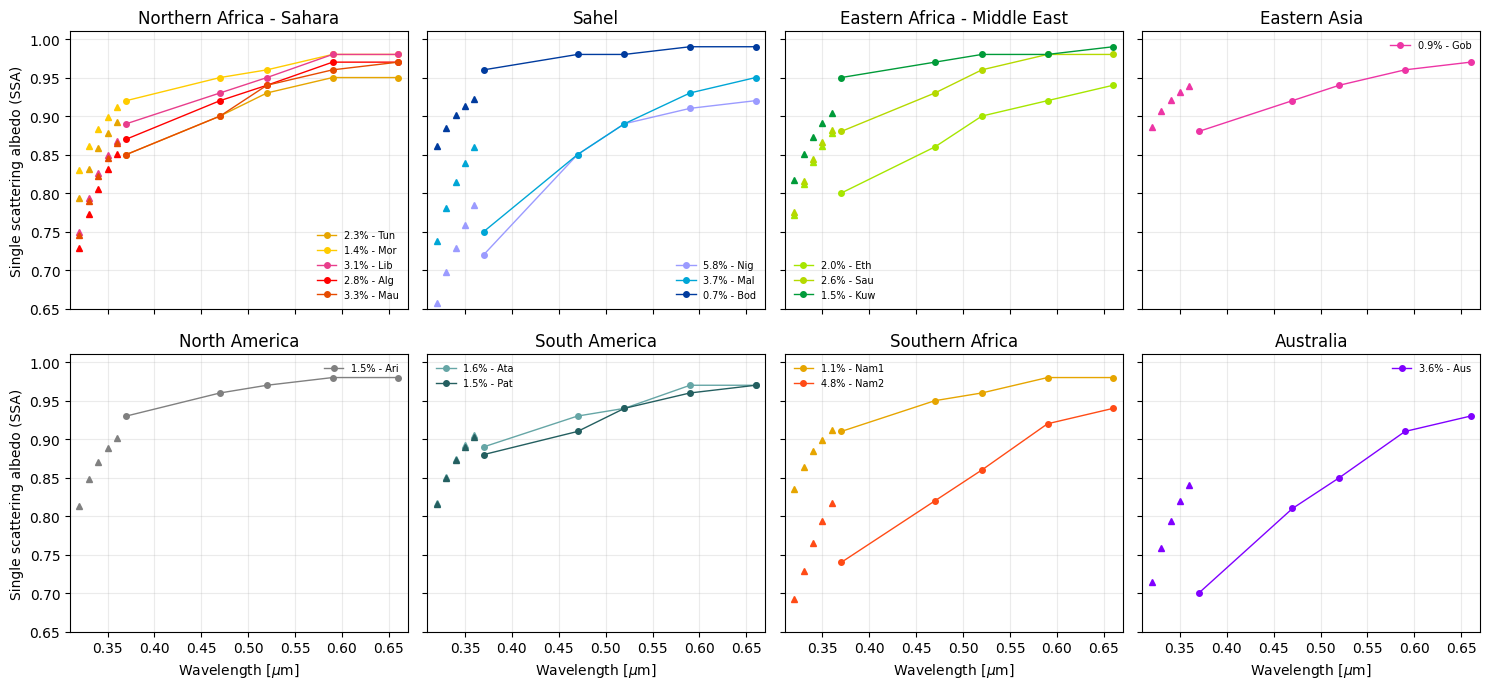

In [17]:
fig, axs = plt.subplots(2, 4, figsize=(15,7), sharex=True, sharey=True)

for ax, (region, ids, cols) in zip(axs.flat, groups):
    for j, c in zip(ids, cols):
        ax.plot(wvl_uv[uv_idx], ssa_uv[j, uv_idx], '^', color=c, ms=5)
        ax.plot(bwvl_ssa, ssa_biri[j], 'o-', color=c, ms=4, lw=1,
                label=f'{bmas[4,j]+bmas[5,j]:.1f}% - {samples[j]}')
    ax.set(title=region, xlim=(0.31,0.67), ylim=(0.65,1.01))
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7, loc='best', frameon=False)

for ax in axs[1,:]: ax.set_xlabel('Wavelength [$\\mu$m]')
for ax in axs[:,0]: ax.set_ylabel('Single scattering albedo (SSA)')

fig.tight_layout()
plt.show()